# 01 · Exploratory data analysis

Goal: understand the data before modeling. Three questions drive this notebook:

1. How rare is fraud? (It decides which metrics make sense.)
2. Do fraudulent transactions differ in `Amount` or in time of day?
3. Is the fraud rate stable over time? (It decides how to split the data.)

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from src.data import TARGET, load_raw

df = load_raw()
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Class balance

In [3]:
counts = df[TARGET].value_counts().rename({0: "legit", 1: "fraud"})
print(counts)
print(f"\nFraud rate: {100 * df[TARGET].mean():.3f}%")
print(f"Accuracy of always predicting 'legit': {100 * (1 - df[TARGET].mean()):.2f}%")

Class
legit    284315
fraud       492
Name: count, dtype: int64

Fraud rate: 0.173%
Accuracy of always predicting 'legit': 99.83%


Fewer than 2 in 1,000 transactions are fraud. A model that never flags anything already reaches 99.8% accuracy, so accuracy tells us nothing. We will judge models on precision, recall and PR-AUC instead (see `src/evaluate.py`).

## 2. Amount by class

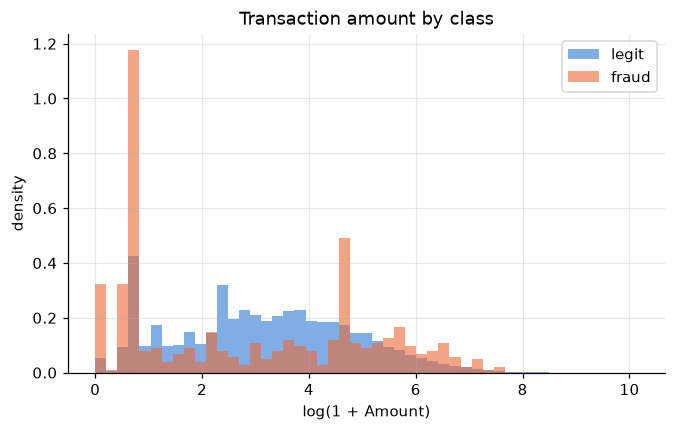

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, np.log1p(df["Amount"].max()), 50)
for label, color, name in [(0, LEGIT, "legit"), (1, FRAUD, "fraud")]:
    ax.hist(np.log1p(df.loc[df[TARGET] == label, "Amount"]), bins=bins, density=True,
            alpha=0.6, color=color, label=name)
ax.set_xlabel("log(1 + Amount)")
ax.set_ylabel("density")
ax.set_title("Transaction amount by class")
ax.legend()
fig.savefig(FIGURES / "eda_amount.png", bbox_inches="tight")

In [5]:
df.groupby(TARGET)["Amount"].describe().rename(index={0: "legit", 1: "fraud"})

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
legit,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
fraud,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


`Amount` is extremely skewed, which is why `src/features.py` applies `log1p` before standardizing. Densities are used instead of counts, otherwise the 492 frauds would be invisible next to 284k legit rows.

Frauds have a *lower* median than legit transactions, and many sit at amounts close to 1 (the tall bar near log(2) ≈ 0.7). That fits a known pattern called card testing: fraudsters make tiny purchases to check that a stolen card works before using it for larger ones.

## 3. Fraud over time

`Time` is the number of seconds since the first transaction, and the dataset covers about two days.

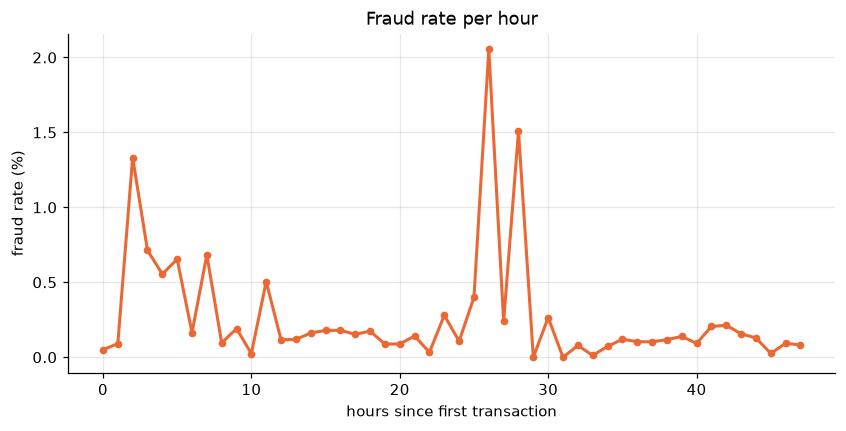

In [6]:
hours = df["Time"] / 3600
by_hour = df.groupby(hours.astype(int))[TARGET].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_hour.index, 100 * by_hour["mean"], color=FRAUD, lw=2, marker="o", ms=4)
ax.set_xlabel("hours since first transaction")
ax.set_ylabel("fraud rate (%)")
ax.set_title("Fraud rate per hour")
fig.savefig(FIGURES / "eda_fraud_rate_over_time.png", bbox_inches="tight")

Text(0.5, 1.0, 'Transaction volume per hour')

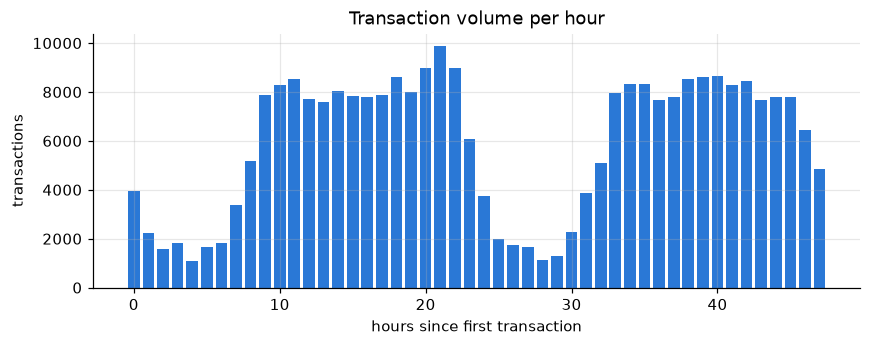

In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(by_hour.index, by_hour["size"], color=LEGIT)
ax.set_xlabel("hours since first transaction")
ax.set_ylabel("transactions")
ax.set_title("Transaction volume per hour")

Two things stand out:

- Volume drops sharply at night (the two dips), while the fraud *rate* spikes in those same hours. Hour of day carries signal, so `src/features.py` turns `Time` into an `hour` feature.
- The fraud rate is not constant over the two days. A split by time (train on the past, test on the future) will expose this drift, which is exactly what a deployed model would face.

## 4. The anonymized features

`V1`..`V28` are PCA components, so they cannot be interpreted directly. We can still check which ones separate the classes the most.

In [8]:
v_cols = [f"V{i}" for i in range(1, 29)]
# Standardized mean difference: how many standard deviations apart the class means are.
diff = (df.loc[df[TARGET] == 1, v_cols].mean() - df.loc[df[TARGET] == 0, v_cols].mean()) / df[v_cols].std()
top = diff.abs().sort_values(ascending=False).head(10)
top

V17    7.861863
V14    7.285436
V12    6.275236
V10    5.222673
V16    4.732777
V3     4.646614
V7     4.509253
V11    3.729500
V4     3.213497
V18    2.684633
dtype: float64

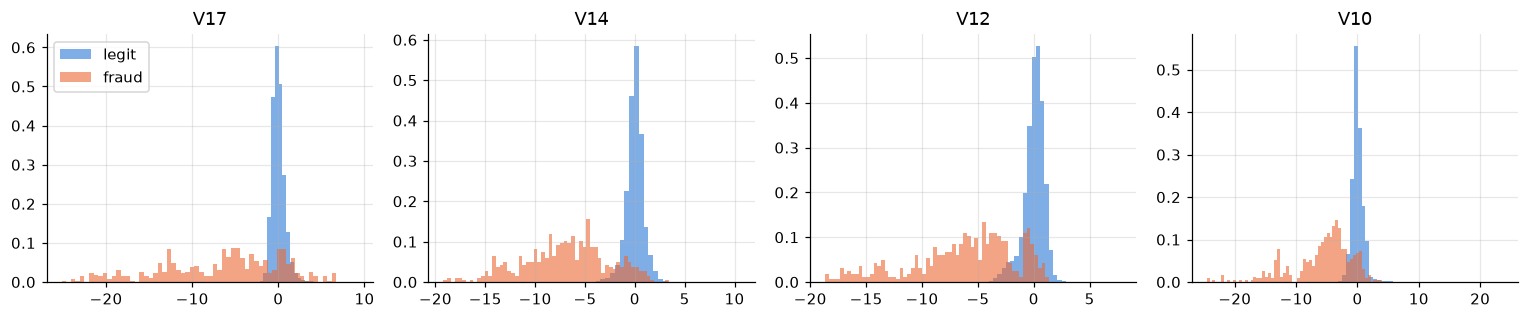

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, top.index[:4]):
    for label, color, name in [(0, LEGIT, "legit"), (1, FRAUD, "fraud")]:
        ax.hist(df.loc[df[TARGET] == label, col], bins=60, density=True, alpha=0.6, color=color, label=name)
    ax.set_title(col)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "eda_top_features.png", bbox_inches="tight")

## Takeaways

- Fraud is 0.17% of the data, so accuracy is meaningless. Use precision, recall and PR-AUC.
- `Amount` needs a log transform; `Time` is more useful as hour of day.
- The fraud rate drifts over time, so we split by time and accept harsher, more honest numbers.
- A handful of PCA components (see the table above) separate the classes well, which suggests even a linear model will be a strong baseline.